In [1]:
!pip install -q pyspark

from pyspark.sql import SparkSession, functions as F
import matplotlib.pyplot as plt

spark = (SparkSession.builder
    .appName("EcommerceAnalytics")
    .master("local[2]")
    .config("spark.driver.memory", "6g")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.driver.maxResultSize", "1g")
    .getOrCreate())
print(spark.version)

4.0.4


- Checking data

In [2]:
import os
print(os.path.exists("/content/online_retail.csv"))

True


In [3]:
raw = spark.read.csv("/content/online_retail.csv", header=True, inferSchema=True)

sales = (raw
    .dropna(subset=["CustomerID", "Description"])
    .filter((F.col("Quantity") > 0) & (F.col("Price") > 0))
    .filter(~F.col("Invoice").cast("string").startswith("C"))
    .select(
        F.col("Invoice").cast("string").alias("order_id"),
        F.col("CustomerID").cast("int").alias("customer_id"),
        F.col("StockCode").cast("string").alias("product_id"),
        F.trim(F.col("Description")).alias("product_name"),
        F.col("Quantity").alias("quantity"),
        F.col("Price").alias("price"),
        F.to_date("InvoiceDate").alias("order_date"))
    .withColumn("revenue", F.col("quantity") * F.col("price"))
    .repartition(8))

print("Rows:", sales.count())

Rows: 805549


In [4]:
# Keep only the 300 most frequently purchased products
top_items = (sales.groupBy("product_name").count()
             .orderBy(F.desc("count")).limit(300))

filtered = sales.join(top_items.select("product_name"), "product_name")

baskets = (filtered.groupBy("order_id")
    .agg(F.collect_set("product_name").alias("items"))
    .filter((F.size("items") >= 2) & (F.size("items") <= 12)))

n_baskets = baskets.count()
print("Baskets:", n_baskets)

Baskets: 22166


In [5]:
from pyspark.ml.fpm import FPGrowth

fp = FPGrowth(itemsCol="items", minSupport=0.02, minConfidence=0.3)
fp_model = fp.fit(baskets)

print("Frequent itemsets (size >= 2):")
fp_model.freqItemsets.filter(F.size("items") >= 2) \
    .orderBy(F.desc("freq")).show(10, truncate=False)

rules = fp_model.associationRules.orderBy(F.desc("lift"))
print("Total rules:", rules.count())
rules.select("antecedent", "consequent", "confidence", "lift", "support") \
     .show(10, truncate=False)

Frequent itemsets (size >= 2):
+----------------------------------------------------------------------+----+
|items                                                                 |freq|
+----------------------------------------------------------------------+----+
|[RED HANGING HEART T-LIGHT HOLDER, WHITE HANGING HEART T-LIGHT HOLDER]|531 |
|[WOODEN PICTURE FRAME WHITE FINISH, WOODEN FRAME ANTIQUE WHITE]       |475 |
+----------------------------------------------------------------------+----+

Total rules: 3
+-----------------------------------+------------------------------------+------------------+------------------+--------------------+
|antecedent                         |consequent                          |confidence        |lift              |support             |
+-----------------------------------+------------------------------------+------------------+------------------+--------------------+
|[WOODEN PICTURE FRAME WHITE FINISH]|[WOODEN FRAME ANTIQUE WHITE]        |0.5806845

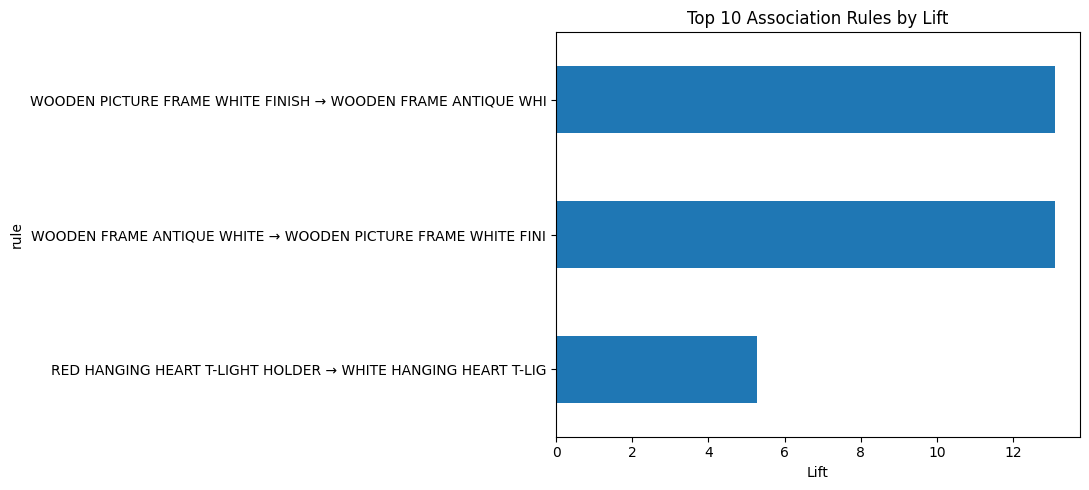

In [6]:
# Visualize
if rules.count() == 0:
    print("No rules. Lower minSupport to 0.01 and re-run the FP-Growth cell.")
else:
    r_pd = rules.limit(10).toPandas()
    r_pd["rule"] = (r_pd.antecedent.apply(lambda x: ", ".join(x)) + " → " +
                    r_pd.consequent.apply(lambda x: ", ".join(x))).str.slice(0, 60)
    r_pd.plot.barh(x="rule", y="lift", figsize=(11, 5), legend=False,
                   title="Top 10 Association Rules by Lift")
    plt.gca().invert_yaxis(); plt.xlabel("Lift")
    plt.tight_layout(); plt.show()

- Exploratory analytics

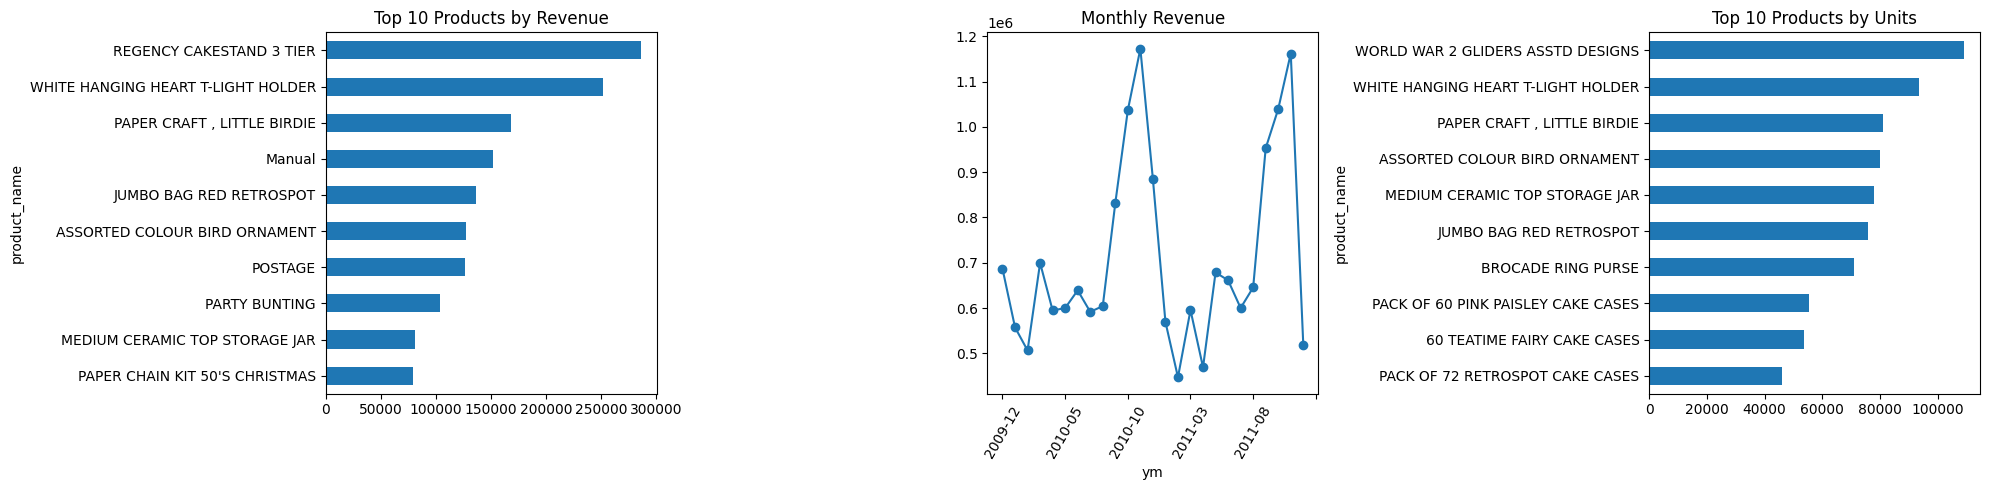

Customers: 5878
Products : 4631
Orders   : 36969


In [7]:
cat_df = sales.groupBy("product_name").agg(F.round(F.sum("revenue"), 2).alias("revenue")) \
              .orderBy(F.desc("revenue")).limit(10).toPandas()

monthly = (sales.withColumn("ym", F.date_format("order_date", "yyyy-MM"))
           .groupBy("ym").agg(F.round(F.sum("revenue"), 2).alias("revenue"))
           .orderBy("ym").toPandas())

top_units = sales.groupBy("product_name").agg(F.sum("quantity").alias("units")) \
                 .orderBy(F.desc("units")).limit(10).toPandas()

fig, ax = plt.subplots(1, 3, figsize=(20, 5))
cat_df.plot.barh(x="product_name", y="revenue", ax=ax[0], legend=False, title="Top 10 Products by Revenue")
monthly.plot(x="ym", y="revenue", marker="o", ax=ax[1], legend=False, title="Monthly Revenue")
ax[1].tick_params(axis="x", rotation=60)
top_units.plot.barh(x="product_name", y="units", ax=ax[2], legend=False, title="Top 10 Products by Units")
for a in (ax[0], ax[2]): a.invert_yaxis()
plt.tight_layout(); plt.show()

print("Customers:", sales.select("customer_id").distinct().count())
print("Products :", sales.select("product_id").distinct().count())
print("Orders   :", sales.select("order_id").distinct().count())

- RFM features

In [8]:
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

ref_date = F.lit("2012-01-01").cast("date")

rfm = sales.groupBy("customer_id").agg(
    F.datediff(ref_date, F.max("order_date")).alias("recency"),
    F.countDistinct("order_id").alias("frequency"),
    F.sum("revenue").alias("monetary")
)

# Log-transform skewed columns so a few wholesalers don't dominate the clusters
rfm = (rfm.withColumn("f_log", F.log1p("frequency"))
          .withColumn("m_log", F.log1p("monetary"))
          .withColumn("r_log", F.log1p("recency"))).cache()

assembler = VectorAssembler(inputCols=["r_log", "f_log", "m_log"], outputCol="raw")
scaler = StandardScaler(inputCol="raw", outputCol="features", withMean=True, withStd=True)
rfm_vec = assembler.transform(rfm)
rfm_scaled = scaler.fit(rfm_vec).transform(rfm_vec).cache()
print("Customers:", rfm_scaled.count())

Customers: 5878


- Choose k (elbow and silhouette)

k=2  WSSSE=8535.3  silhouette=0.624
k=3  WSSSE=5993.3  silhouette=0.550
k=4  WSSSE=4625.6  silhouette=0.556
k=5  WSSSE=3686.1  silhouette=0.543
k=6  WSSSE=3312.0  silhouette=0.479
k=7  WSSSE=2878.3  silhouette=0.469
k=8  WSSSE=2657.1  silhouette=0.462


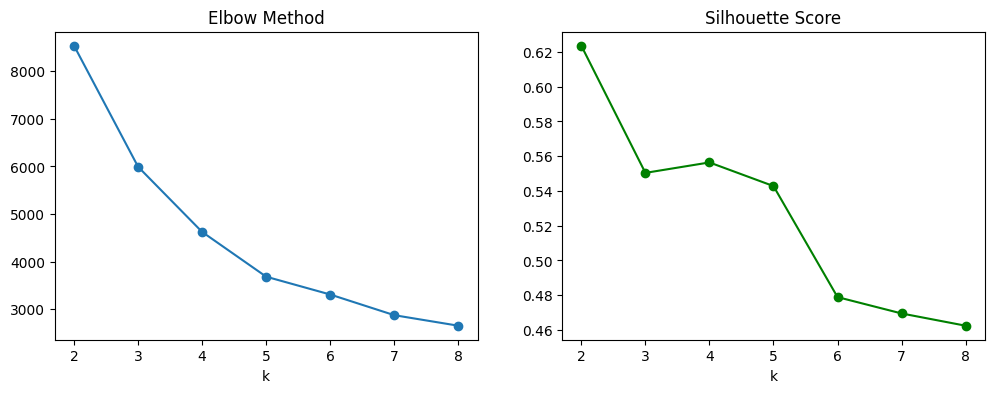

In [9]:
evaluator = ClusteringEvaluator(featuresCol="features", metricName="silhouette")
ks, wssse, sil = [], [], []
for k in range(2, 9):
    m = KMeans(k=k, seed=1, featuresCol="features").fit(rfm_scaled)
    ks.append(k)
    wssse.append(m.summary.trainingCost)
    sil.append(evaluator.evaluate(m.transform(rfm_scaled)))
    print(f"k={k}  WSSSE={wssse[-1]:.1f}  silhouette={sil[-1]:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, wssse, marker="o"); ax[0].set_title("Elbow Method"); ax[0].set_xlabel("k")
ax[1].plot(ks, sil, marker="o", color="green"); ax[1].set_title("Silhouette Score"); ax[1].set_xlabel("k")
plt.show()

- Final K-Means model and segment profiles

Silhouette: 0.556
+-------+---------+----------------+----------+---------+
|segment|customers|avg_recency_days|avg_orders|avg_spend|
+-------+---------+----------------+----------+---------+
|      0|     1366|            56.1|      17.9|   9998.0|
|      1|     1700|           450.7|       1.3|    295.6|
|      2|     1211|           309.7|       4.5|   1812.5|
|      3|     1601|            61.3|       3.0|    867.5|
+-------+---------+----------------+----------+---------+



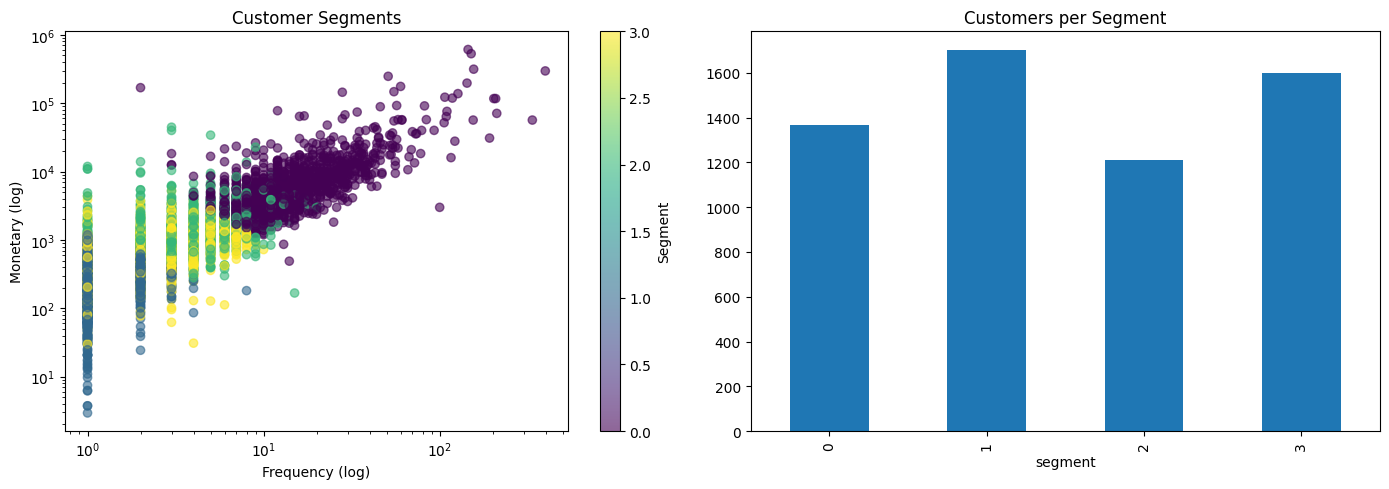

In [10]:
# k=4 gives interpretable business segments; change it if the silhouette plot strongly favours another value
best_k = 4
km = KMeans(k=best_k, seed=1, featuresCol="features").fit(rfm_scaled)
segments = km.transform(rfm_scaled).withColumnRenamed("prediction", "segment").cache()
print("Silhouette:", round(evaluator.evaluate(km.transform(rfm_scaled)), 3))

profile = segments.groupBy("segment").agg(
    F.count("*").alias("customers"),
    F.round(F.avg("recency"), 1).alias("avg_recency_days"),
    F.round(F.avg("frequency"), 1).alias("avg_orders"),
    F.round(F.avg("monetary"), 1).alias("avg_spend")
).orderBy("segment")
profile.show()

seg_pd = segments.select("recency", "frequency", "monetary", "segment").toPandas()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sc = ax[0].scatter(seg_pd.frequency, seg_pd.monetary, c=seg_pd.segment, cmap="viridis", alpha=0.6)
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("Frequency (log)"); ax[0].set_ylabel("Monetary (log)"); ax[0].set_title("Customer Segments")
plt.colorbar(sc, ax=ax[0], label="Segment")
seg_pd.segment.value_counts().sort_index().plot.bar(ax=ax[1], title="Customers per Segment")
plt.tight_layout(); plt.show()

- Prepare data for ALS

In [11]:
from pyspark.ml.feature import StringIndexer

indexer = StringIndexer(inputCol="product_id", outputCol="pid_idx", handleInvalid="skip").fit(sales)

interactions = (indexer.transform(sales)
    .groupBy("customer_id", "pid_idx").agg(F.sum("quantity").alias("rating"))
    .withColumn("product_id", F.col("pid_idx").cast("int"))
    .select("customer_id", "product_id", F.col("rating").cast("float"))
    .cache())

print("Interactions:", interactions.count())

# Lookup table: index -> readable product name
prod_lookup = (indexer.transform(sales)
    .groupBy(F.col("pid_idx").cast("int").alias("product_id"))
    .agg(F.first("product_name").alias("product_name"),
         F.round(F.avg("price"), 2).alias("price")))

Interactions: 481932


- Train ALS

In [12]:
from pyspark.ml.recommendation import ALS

train, test = interactions.randomSplit([0.8, 0.2], seed=42)

als = ALS(userCol="customer_id", itemCol="product_id", ratingCol="rating",
          implicitPrefs=True, rank=10, maxIter=10, regParam=0.1, alpha=20.0,
          coldStartStrategy="drop", nonnegative=True, seed=42)
als_model = als.fit(train)
print("ALS trained. Rank:", als_model.rank)

ALS trained. Rank: 10


- Ranking evaluation (Precision@K, Recall@K, NDCG@K)

In [13]:
from pyspark.ml.evaluation import RankingEvaluator

K = 10
truth = test.groupBy("customer_id") \
            .agg(F.collect_list(F.col("product_id").cast("double")).alias("label"))

pred = als_model.recommendForUserSubset(truth.select("customer_id"), K) \
    .select("customer_id", F.col("recommendations.product_id").cast("array<double>").alias("prediction"))

joined = pred.join(truth, "customer_id")

results = {}
for metric in ["precisionAtK", "recallAtK", "ndcgAtK", "meanAveragePrecision"]:
    ev = RankingEvaluator(metricName=metric, k=K) if metric != "meanAveragePrecision" \
         else RankingEvaluator(metricName=metric)
    results[metric] = ev.evaluate(joined)
    print(f"{metric}: {results[metric]:.4f}")

precisionAtK: 0.0204
recallAtK: 0.0214
ndcgAtK: 0.0227
meanAveragePrecision: 0.0060



Popularity baseline:
precisionAtK: 0.0244
recallAtK: 0.0196
ndcgAtK: 0.0261


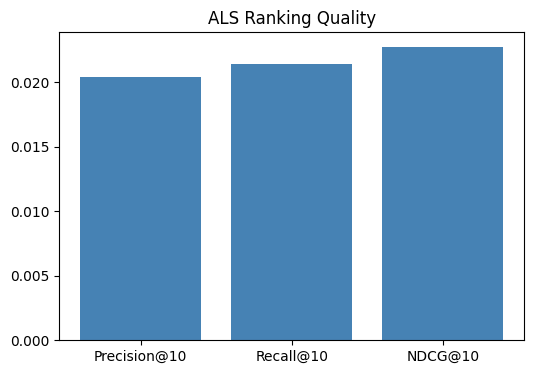

In [14]:
# Baseline comparison: recommend the K most popular items to everyone
pop = train.groupBy("product_id").agg(F.sum("rating").alias("s")) \
           .orderBy(F.desc("s")).limit(K)
pop_ids = [float(r.product_id) for r in pop.collect()]

pop_pred = truth.select("customer_id", "label") \
    .withColumn("prediction", F.array(*[F.lit(x) for x in pop_ids]))

print("\nPopularity baseline:")
for metric in ["precisionAtK", "recallAtK", "ndcgAtK"]:
    print(f"{metric}: {RankingEvaluator(metricName=metric, k=K).evaluate(pop_pred):.4f}")

plt.figure(figsize=(6, 4))
plt.bar(["Precision@10", "Recall@10", "NDCG@10"],
        [results["precisionAtK"], results["recallAtK"], results["ndcgAtK"]], color="steelblue")
plt.title("ALS Ranking Quality"); plt.show()

- Personalized recommendations

In [15]:
recs = als_model.recommendForAllUsers(5)
recs_flat = (recs.select("customer_id", F.explode("recommendations").alias("rec"))
    .select("customer_id", F.col("rec.product_id").alias("product_id"),
            F.round("rec.rating", 3).alias("score"))
    .join(prod_lookup, "product_id"))

sample_cust = interactions.select("customer_id").first()["customer_id"]
print("Recommendations for customer", sample_cust)
recs_flat.filter(F.col("customer_id") == sample_cust) \
         .select("product_name", "price", "score").orderBy(F.desc("score")).show(truncate=False)

print("What this customer already bought (top 5):")
(sales.filter(F.col("customer_id") == sample_cust)
      .groupBy("product_name").agg(F.sum("quantity").alias("qty"))
      .orderBy(F.desc("qty")).show(5, truncate=False))

Recommendations for customer 17865
+----------------------------------+-----+-----+
|product_name                      |price|score|
+----------------------------------+-----+-----+
|SMALL CHINESE STYLE SCISSOR       |0.4  |1.593|
|ASSORTED WHITE EMBOSSED CHINA MUGS|2.06 |1.112|
|SMALL CHUNKY GLASS ROMAN  BOWL    |2.03 |1.075|
|MIRRORED DISCO BALL               |5.79 |1.074|
|ASSORTED LAQUERED INCENSE HOLDERS |0.2  |1.069|
+----------------------------------+-----+-----+

What this customer already bought (top 5):
+------------------------------+---+
|product_name                  |qty|
+------------------------------+---+
|AREA PATROLLED METAL SIGN     |816|
|BEWARE OF THE CAT METAL SIGN  |456|
|STRAWBERRY CERAMIC TRINKET BOX|384|
|BLUE SPOT CERAMIC DRAWER KNOB |318|
|GIN + TONIC DIET METAL SIGN   |312|
+------------------------------+---+
only showing top 5 rows


- Content-based filtering (TF-IDF on product descriptions)

In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

prod_pd = (sales.groupBy("product_id")
           .agg(F.first("product_name").alias("product_name"))
           .toPandas().reset_index(drop=True))
print("Products:", len(prod_pd))

tfidf = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2)
tfidf_matrix = tfidf.fit_transform(prod_pd.product_name.str.lower())

def similar_products(name, n=5):
    matches = prod_pd.index[prod_pd.product_name.str.contains(name, case=False, regex=False)]
    if len(matches) == 0:
        return "No product matched."
    i = matches[0]
    sims = cosine_similarity(tfidf_matrix[i], tfidf_matrix).ravel()
    top = sims.argsort()[::-1][1:n+1]
    out = prod_pd.iloc[top][["product_name"]].copy()
    out["similarity"] = sims[top].round(3)
    print("Query product:", prod_pd.iloc[i].product_name)
    return out

similar_products("LUNCH BAG")

Products: 4631
Query product: LUNCH BAG RED SPOTTY


,product_name,similarity
2719,LUNCH BAG RED VINTAGE DOILY,0.613
253,LUNCH BAG CARS BLUE,0.604
1544,TEA BAG PLATE RED SPOTTY,0.511
254,RED SPOTTY CANDY BAG,0.457
251,LUNCH BAG WOODLAND,0.456


- Hybrid cross-sell (segment and association rules)

In [17]:
# Pick a customer, show their segment, and cross-sell using FP-Growth rules
cust = sample_cust
seg = segments.filter(F.col("customer_id") == cust).select("segment").first()["segment"]
print(f"Customer {cust} belongs to segment {seg}")

bought = [r.product_name for r in sales.filter(F.col("customer_id") == cust)
          .select("product_name").distinct().collect()]

rules_pd = rules.select("antecedent", "consequent", "confidence", "lift").toPandas()
hits = rules_pd[rules_pd.antecedent.apply(lambda a: all(x in bought for x in a))]
hits = hits[hits.consequent.apply(lambda c: not any(x in bought for x in c))]

print("\nRule-based cross-sell suggestions:")
print(hits.sort_values("lift", ascending=False).head(5).to_string(index=False))

Customer 17865 belongs to segment 0

Rule-based cross-sell suggestions:
Empty DataFrame
Columns: [antecedent, consequent, confidence, lift]
Index: []
